In [1]:

import random
import pandas as pd

# Settings
random.seed(42)
numbers = list(range(1, 11))
num_trials = 100
sample_size = 10

results = []

# Generate 100 bootstrap samples
for trial in range(1, num_trials + 1):

    # Sampling WITH replacement
    sample = random.choices(numbers, k=sample_size)

    # Count occurrences of each number
    counts = {num: sample.count(num) for num in numbers}

    # Number of repeated selections beyond first occurrences
    repeated_count = sum(count - 1 for count in counts.values()
                         if count > 1)

    # Numbers selected at least once
    selected = set(sample)
    distinct_count = len(selected)

    # Numbers not selected (out-of-bag)
    oob_numbers = sorted(set(numbers) - selected)
    oob_count = len(oob_numbers)

    # Probabilities / proportions
    repeat_probability = repeated_count / sample_size
    oob_probability = oob_count / len(numbers)

    # Store the results
    results.append({
        "Trial": trial,
        "Sample": sample,
        "Repeated_Count": repeated_count,
        "Repeated_Numbers": sorted(
            num for num, count in counts.items() if count > 1
        ),
        "Distinct_Count": distinct_count,
        "OOB_Numbers": oob_numbers,
        "OOB_Count": oob_count,
        "Repeat_Rate": repeat_probability,
        "OOB_Probability": oob_probability
    })

# Create the dataset
df = pd.DataFrame(results)

# Display all 100 trials
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)

print("SYNTHETIC BOOTSTRAP DATASET")
print(df.to_string(index=False))

# Save the complete dataset to a CSV file
df.to_csv("bootstrap_dataset.csv", index=False)

# Summary statistics
print("\nOVERALL SUMMARY")
print("Total trials:", num_trials)
print("Total selections:", num_trials * sample_size)
print("Trials with repeats:",
      (df["Repeated_Count"] > 0).sum())
print("Trials with OOB numbers:",
      (df["OOB_Count"] > 0).sum())
print("Average repeated-selection rate:",
      round(df["Repeat_Rate"].mean() * 100, 2), "%")
print("Average OOB probability:",
      round(df["OOB_Probability"].mean() * 100, 2), "%")
print("Average distinct numbers per sample:",
      round(df["Distinct_Count"].mean(), 2))


SYNTHETIC BOOTSTRAP DATASET
 Trial                             Sample  Repeated_Count Repeated_Numbers  Distinct_Count         OOB_Numbers  OOB_Count  Repeat_Rate  OOB_Probability
     1     [7, 1, 3, 3, 8, 7, 9, 1, 5, 1]               4        [1, 3, 7]               6       [2, 4, 6, 10]          4          0.4              0.4
     2     [3, 6, 1, 2, 7, 6, 3, 6, 9, 1]               4        [1, 3, 6]               6       [4, 5, 8, 10]          4          0.4              0.4
     3    [9, 7, 4, 2, 10, 4, 1, 1, 9, 7]               4     [1, 4, 7, 9]               6        [3, 5, 6, 8]          4          0.4              0.4
     4    [9, 8, 6, 10, 4, 6, 9, 7, 9, 6]               4           [6, 9]               6        [1, 2, 3, 5]          4          0.4              0.4
     5     [8, 1, 3, 3, 1, 3, 2, 3, 7, 4]               4           [1, 3]               6       [5, 6, 9, 10]          4          0.4              0.4
     6    [4, 3, 3, 10, 7, 7, 2, 8, 2, 4]               4   

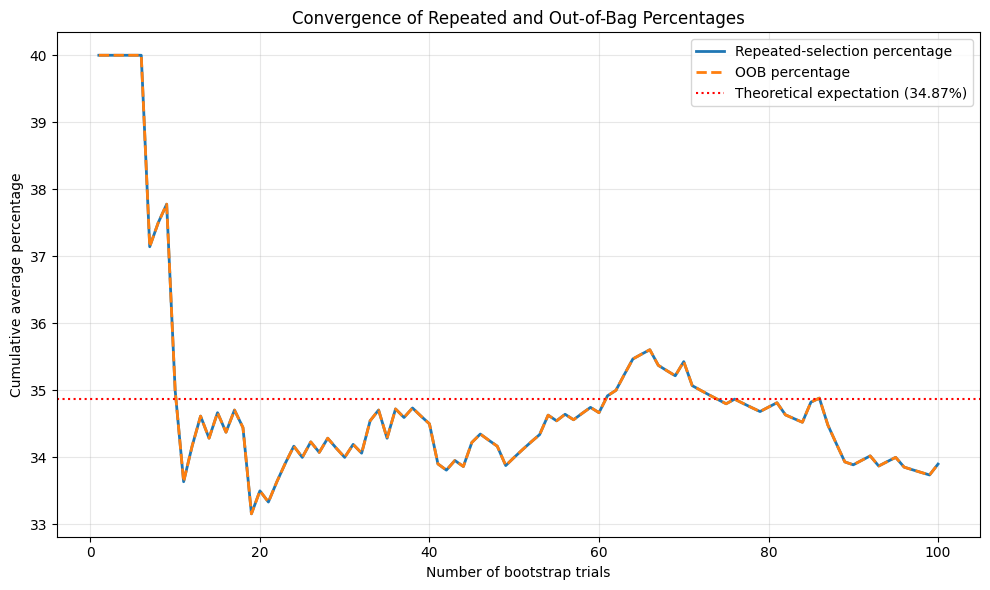

In [2]:
import matplotlib.pyplot as plt

# Running averages after each trial
df["Cumulative_Repeat_Percentage"] = (
    df["Repeat_Rate"].expanding().mean() * 100
)
df["Cumulative_OOB_Percentage"] = (
    df["OOB_Probability"].expanding().mean() * 100
)

plt.figure(figsize=(10, 6))

plt.plot(
    df["Trial"],
    df["Cumulative_Repeat_Percentage"],
    label="Repeated-selection percentage",
    linewidth=2
)

plt.plot(
    df["Trial"],
    df["Cumulative_OOB_Percentage"],
    linestyle="--",
    label="OOB percentage",
    linewidth=2
)

plt.axhline(
    34.87,
    color="red",
    linestyle=":",
    label="Theoretical expectation (34.87%)"
)

plt.xlabel("Number of bootstrap trials")
plt.ylabel("Cumulative average percentage")
plt.title("Convergence of Repeated and Out-of-Bag Percentages")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()